# Zenodo oral-cavity dataset -- patient-level train / val / test split

Splits your dataset into **train / val / test at the PATIENT level**, not the
image level, so no patient's images end up in more than one split (which
would leak the same mouth/lesion across train and test and inflate your
metrics). Full explanation of why patient-level matters is in Section 3.

This notebook:
1. Reads `Imagewise_Data.csv` (image -> category) and derives each image's
   `patient_id` from its filename.
2. Does a **stratified group split** -- patient is the group (never split
   across sets), category is what gets stratified so train/val/test each
   keep a similar class mix.
3. **Verifies zero patient leakage** across the three splits (hard assertion,
   not just a print).
4. Prints and charts exactly how many **images** and how many **patients**
   landed in each split, broken down **by category** (Healthy/Benign/OPMD/OCA).
5. Physically copies (never moves, never deletes) every image into
   `<output>/train/<Category>/...`, `<output>/val/<Category>/...`,
   `<output>/test/<Category>/...`, preserving the original filename.
6. Saves a full CSV log (`split_assignment.csv`) with one row per image:
   patient id, category, split, source path, destination path -- your
   permanent record of exactly what went where.

**Nothing in your source folder is ever moved or deleted** -- every file
operation here is a copy.

### Before you run this
You'll need `Imagewise_Data.csv` and the folder of images you want split
(this can be the original Zenodo `Images/` folder, or the
`segmented_oral_cavity/` folder from the segmentation notebook -- either
works, since the split logic only cares about filenames, not pixel content).
Optionally `Patientwise_Data.csv` too, if you want patient demographics
(age/gender/smoking/etc.) merged into the log.


In [1]:
# ============================================================
# 1. CONFIG -- enter your paths when prompted
# ============================================================
from pathlib import Path


def ask_path(prompt, must_exist=True, is_file=False, allow_blank=False):
    while True:
        raw = input(prompt).strip().strip('"').strip("'")
        if not raw:
            if allow_blank:
                return None
            print("  -> can't be empty, try again.")
            continue
        p = Path(raw).expanduser()
        if must_exist and not p.exists():
            print(f"  -> {p} doesn't exist, try again.")
            continue
        if must_exist and is_file and not p.is_file():
            print(f"  -> {p} exists but isn't a file, try again.")
            continue
        if must_exist and not is_file and not p.is_dir():
            print(f"  -> {p} exists but isn't a folder, try again.")
            continue
        return p


IMAGEWISE_CSV = ask_path("Path to Imagewise_Data.csv: ", must_exist=True, is_file=True)
PATIENTWISE_CSV = ask_path(
    "Path to Patientwise_Data.csv (optional -- adds demographics to the log; Enter to skip): ",
    must_exist=True, is_file=True, allow_blank=True)
SOURCE_IMAGES_DIR = ask_path(
    "Path to the folder of images you want split (e.g. Images/ or segmented_oral_cavity/): ",
    must_exist=True, is_file=False)
OUTPUT_DIR = ask_path("Output folder for the train/val/test split (created if missing): ", must_exist=False)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --- split fractions -- must sum to 1.0 ---
TRAIN_FRAC = 0.70
VAL_FRAC   = 0.15
TEST_FRAC  = 0.15
assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1.0) < 1e-9, "TRAIN/VAL/TEST fractions must sum to 1.0"

RANDOM_SEED = 42
SOURCE_EXTS = [".jpg", ".jpeg", ".png"]   # tried in this order when locating each image on disk

print()
print("Imagewise CSV   :", IMAGEWISE_CSV)
print("Patientwise CSV :", PATIENTWISE_CSV if PATIENTWISE_CSV else "(skipped)")
print("Source images   :", SOURCE_IMAGES_DIR)
print("Output folder   :", OUTPUT_DIR)
print(f"Split           : train {TRAIN_FRAC:.0%} / val {VAL_FRAC:.0%} / test {TEST_FRAC:.0%}")



Imagewise CSV   : /Users/annapoornaak/Desktop/College /Oral Cancer/Dataset/Zenodo/Dataset/Imagewise_Data.csv
Patientwise CSV : /Users/annapoornaak/Desktop/College /Oral Cancer/Dataset/Zenodo/Dataset/Patientwise_Data.csv
Source images   : /Users/annapoornaak/Desktop/College /Oral Cancer/Code Files/After fine tuning mobileunet/output with segmented oral cavity v2/segmented_oral_cavity_cropped
Output folder   : /Users/annapoornaak/Desktop/College /Oral Cancer/Code Files/After fine tuning mobileunet/train test vali zenodo
Split           : train 70% / val 15% / test 15%


In [2]:
# ============================================================
# 2. IMPORTS + LOAD METADATA
# ============================================================
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold

df = pd.read_csv(IMAGEWISE_CSV)
df["Image Name"] = df["Image Name"].astype(str)
print(f"Loaded {len(df)} image records from {IMAGEWISE_CSV.name}")
print("Categories:", sorted(df["Category"].unique()))

if PATIENTWISE_CSV:
    patients_df = pd.read_csv(PATIENTWISE_CSV)
    patients_df.columns = [c.strip() for c in patients_df.columns]
    print(f"Loaded {len(patients_df)} patient records from {PATIENTWISE_CSV.name}")
else:
    patients_df = None


Loaded 3000 image records from Imagewise_Data.csv
Categories: ['Benign', 'Healthy', 'OCA', 'OPMD']
Loaded 714 patient records from Patientwise_Data.csv


In [3]:
# ============================================================
# 3. WHY PATIENT-LEVEL (not image-level)
# ============================================================
# Each patient contributes several images (same mouth, same lesion, same
# lighting/camera -- often near-duplicate framing). An IMAGE-level split can
# put two images of the SAME patient's SAME lesion into train and test. The
# model can then partly learn to recognize the *patient*, not the lesion --
# your test metrics come out inflated in a way that won't hold on a truly
# new patient. This is one of the most common silent leakage bugs in medical
# imaging datasets, and it's why every split below operates on `patient_id`,
# never on individual images.

def patient_id_from_image_name(name: str) -> str:
    # "R-01-01" -> "R-01"  |  "C-10-12-5" -> "C-10"
    # (patient id is always the first two dash-separated fields, verified
    # against Patientwise_Data.csv's own Patient ID column below)
    parts = name.split("-")
    return f"{parts[0]}-{parts[1]}"

df["patient_id"] = df["Image Name"].apply(patient_id_from_image_name)

if patients_df is not None:
    id_col = "Patient ID" if "Patient ID" in patients_df.columns else patients_df.columns[0]
    known_patients = set(patients_df[id_col].astype(str))
    derived_patients = set(df["patient_id"])
    unmatched = derived_patients - known_patients
    print(f"Patients derived from filenames : {len(derived_patients)}")
    print(f"Patients listed in {PATIENTWISE_CSV.name}: {len(known_patients)}")
    print(f"Derived patient IDs NOT found in Patientwise_Data.csv: {len(unmatched)}",
          sorted(unmatched)[:15] if unmatched else "")
    print("(A handful of mismatches can be normal filename quirks -- check the sample above",
          "before trusting the split if this number is large.)")
else:
    print(f"{df['patient_id'].nunique()} unique patients derived from filenames.")
    print("(Patientwise_Data.csv not provided -- skipping the cross-check against its Patient ID column.)")


Patients derived from filenames : 714
Patients listed in Patientwise_Data.csv: 714
Derived patient IDs NOT found in Patientwise_Data.csv: 0 
(A handful of mismatches can be normal filename quirks -- check the sample above before trusting the split if this number is large.)


In [4]:
# ============================================================
# 4. PATIENT-LEVEL STRATIFIED GROUP SPLIT
#    Group = patient_id (a patient's images never split across sets).
#    Stratify = the patient's dominant category, so train/val/test each keep
#    a similar class balance.
# ============================================================
patient_summary = (
    df.groupby("patient_id")["Category"]
      .agg(lambda s: s.mode().iloc[0])
      .reset_index()
      .rename(columns={"Category": "dominant_category"})
)
n_images_per_patient = df.groupby("patient_id").size().rename("n_images")
patient_summary = patient_summary.merge(n_images_per_patient, on="patient_id")

print(f"{len(patient_summary)} unique patients.")
print(patient_summary["dominant_category"].value_counts())

# Stage 1: train vs. (val+test)
holdout_frac = VAL_FRAC + TEST_FRAC
n_splits_1 = max(2, round(1 / holdout_frac))
sgkf1 = StratifiedGroupKFold(n_splits=n_splits_1, shuffle=True, random_state=RANDOM_SEED)
train_idx, temp_idx = next(sgkf1.split(
    patient_summary, patient_summary["dominant_category"], groups=patient_summary["patient_id"]))
train_patients = set(patient_summary.iloc[train_idx]["patient_id"])
temp_patients_df = patient_summary.iloc[temp_idx].reset_index(drop=True)

# Stage 2: split the (val+test) remainder proportionally to VAL_FRAC : TEST_FRAC
val_share_of_temp = VAL_FRAC / holdout_frac
n_splits_2 = max(2, round(1 / min(val_share_of_temp, 1 - val_share_of_temp)))
sgkf2 = StratifiedGroupKFold(n_splits=n_splits_2, shuffle=True, random_state=RANDOM_SEED)
part_a_idx, part_b_idx = next(sgkf2.split(
    temp_patients_df, temp_patients_df["dominant_category"], groups=temp_patients_df["patient_id"]))
part_a_patients = set(temp_patients_df.iloc[part_a_idx]["patient_id"])
part_b_patients = set(temp_patients_df.iloc[part_b_idx]["patient_id"])
# whichever part is closer to VAL_FRAC's share becomes val, the other test
if abs(len(part_a_idx) / len(temp_patients_df) - val_share_of_temp) <= \
   abs(len(part_b_idx) / len(temp_patients_df) - val_share_of_temp):
    val_patients, test_patients = part_a_patients, part_b_patients
else:
    val_patients, test_patients = part_b_patients, part_a_patients


def split_of(pid):
    if pid in train_patients: return "train"
    if pid in val_patients:   return "val"
    if pid in test_patients:  return "test"
    return "unassigned"


df["split"] = df["patient_id"].apply(split_of)
patient_summary["split"] = patient_summary["patient_id"].apply(split_of)

n_unassigned = int((df["split"] == "unassigned").sum())
print(f"\\nUnassigned images (should be 0): {n_unassigned}")
assert n_unassigned == 0, "Some images/patients weren't assigned to a split -- investigate before continuing."


714 unique patients.
dominant_category
OPMD       288
Benign     220
Healthy    160
OCA         46
Name: count, dtype: int64
\nUnassigned images (should be 0): 0


In [5]:
# ============================================================
# 5. LEAKAGE CHECK -- hard assertion, not just a print
# ============================================================
splits = ["train", "val", "test"]
leaks_found = []
for a in splits:
    for b in splits:
        if a < b:
            pa = set(df.loc[df.split == a, "patient_id"])
            pb = set(df.loc[df.split == b, "patient_id"])
            overlap = pa & pb
            if overlap:
                leaks_found.append((a, b, overlap))

if leaks_found:
    for a, b, overlap in leaks_found:
        print(f"LEAK between {a} and {b}: {overlap}")
    raise AssertionError("Patient leakage detected across splits -- do not proceed until this is 0.")
else:
    print("No patient leakage across train/val/test -- confirmed.")
    print("Every one of a patient's images is in exactly one split.")


No patient leakage across train/val/test -- confirmed.
Every one of a patient's images is in exactly one split.


In [6]:
# ============================================================
# 6. COUNTS -- images and patients per split, broken down by category
# ============================================================
print("=" * 60)
print("IMAGE counts per split:")
print(df["split"].value_counts().reindex(splits))
print()
print("IMAGE counts per split x category:")
image_counts = pd.crosstab(df["split"], df["Category"]).reindex(splits)
image_counts["TOTAL"] = image_counts.sum(axis=1)
print(image_counts)
print()
print("Row-normalized (class balance check -- splits should look similar down each column):")
print(pd.crosstab(df["split"], df["Category"], normalize="index").reindex(splits).round(3))
print()
print("=" * 60)
print("PATIENT counts per split:")
print(patient_summary["split"].value_counts().reindex(splits))
print()
print("PATIENT counts per split x dominant category:")
patient_counts = pd.crosstab(patient_summary["split"], patient_summary["dominant_category"]).reindex(splits)
patient_counts["TOTAL"] = patient_counts.sum(axis=1)
print(patient_counts)


IMAGE counts per split:
split
train    1933
val       517
test      550
Name: count, dtype: int64

IMAGE counts per split x category:
Category  Benign  Healthy  OCA  OPMD  TOTAL
split                                      
train        492      481   76   884   1933
val          128      123   16   250    517
test         128      125   37   260    550

Row-normalized (class balance check -- splits should look similar down each column):
Category  Benign  Healthy    OCA   OPMD
split                                  
train      0.255    0.249  0.039  0.457
val        0.248    0.238  0.031  0.484
test       0.233    0.227  0.067  0.473

PATIENT counts per split:
split
train    476
val      119
test     119
Name: count, dtype: int64

PATIENT counts per split x dominant category:
dominant_category  Benign  Healthy  OCA  OPMD  TOTAL
split                                               
train                 147      107   30   192    476
val                    36       27    8    48    119
tes

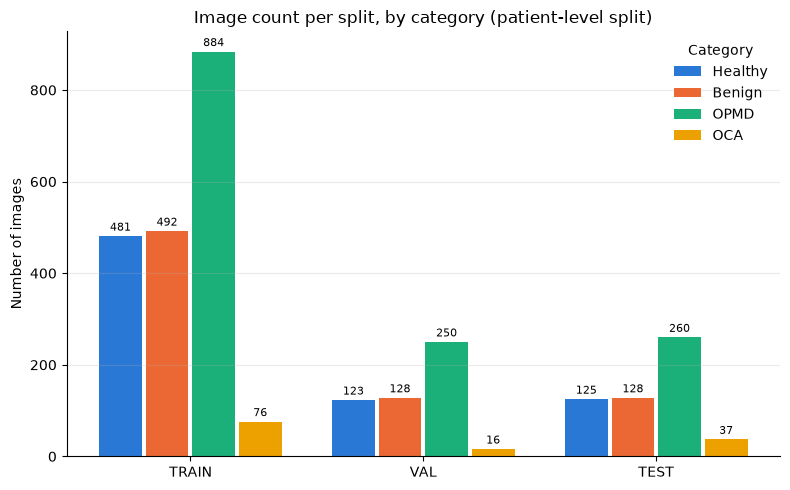

Saved chart to: /Users/annapoornaak/Desktop/College /Oral Cancer/Code Files/After fine tuning mobileunet/train test vali zenodo/split_counts_by_category.png


In [7]:
# ============================================================
# 7. CHART -- image counts per split, by category
#    Categorical color assigned by identity (category), fixed order, never
#    cycled -- same 4 colors used consistently across all three split groups.
# ============================================================
CATEGORY_ORDER = [c for c in ["Healthy", "Benign", "OPMD", "OCA"] if c in image_counts.columns]
CATEGORY_COLORS = {
    "Healthy": "#2a78d6",   # slot 1 -- blue
    "Benign":  "#eb6834",   # slot 2 -- orange
    "OPMD":    "#1baf7a",   # slot 3 -- aqua
    "OCA":     "#eda100",   # slot 4 -- yellow
}

x = np.arange(len(splits))
n_cats = len(CATEGORY_ORDER)
bar_width = 0.8 / n_cats

fig, ax = plt.subplots(figsize=(8, 5))
for i, cat in enumerate(CATEGORY_ORDER):
    values = [image_counts.loc[s, cat] if cat in image_counts.columns else 0 for s in splits]
    offsets = x - 0.4 + bar_width * (i + 0.5)
    bars = ax.bar(offsets, values, width=bar_width * 0.92, label=cat,
                   color=CATEGORY_COLORS.get(cat, "#999999"))
    ax.bar_label(bars, fontsize=8, padding=2)

ax.set_xticks(x); ax.set_xticklabels([s.upper() for s in splits])
ax.set_ylabel("Number of images")
ax.set_title("Image count per split, by category (patient-level split)")
ax.legend(title="Category", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()

chart_path = OUTPUT_DIR / "split_counts_by_category.png"
fig.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved chart to:", chart_path)


In [8]:
# ============================================================
# 8. PHYSICALLY COPY FILES INTO <output>/<split>/<category>/
#    COPY only -- never move, never delete. Source folder is untouched.
# ============================================================
def find_source_file(stem):
    for ext in SOURCE_EXTS:
        p = SOURCE_IMAGES_DIR / f"{stem}{ext}"
        if p.exists():
            return p
    return None

copy_rows = []
missing = []

for split in splits:
    for cat in df["Category"].unique():
        (OUTPUT_DIR / split / cat).mkdir(parents=True, exist_ok=True)

for _, row in df.iterrows():
    stem = row["Image Name"]
    src = find_source_file(stem)
    if src is None:
        missing.append(stem)
        continue
    dest = OUTPUT_DIR / row["split"] / row["Category"] / src.name
    shutil.copy2(src, dest)   # copy2 preserves metadata; source file is untouched
    copy_rows.append({
        "image_name": stem,
        "patient_id": row["patient_id"],
        "category": row["Category"],
        "split": row["split"],
        "source_path": str(src),
        "dest_path": str(dest),
    })

print(f"Copied {len(copy_rows)} files.")
if missing:
    print(f"WARNING -- {len(missing)} images listed in the CSV were not found in {SOURCE_IMAGES_DIR}:")
    print(missing[:20])


Copied 3000 files.


In [9]:
# ============================================================
# 9. SAVE THE FULL SPLIT LOG (your permanent record of what went where)
# ============================================================
log_df = pd.DataFrame(copy_rows)

if patients_df is not None:
    id_col = "Patient ID" if "Patient ID" in patients_df.columns else patients_df.columns[0]
    log_df = log_df.merge(patients_df, left_on="patient_id", right_on=id_col, how="left")

log_csv_path = OUTPUT_DIR / "split_assignment.csv"
log_df.to_csv(log_csv_path, index=False)

patient_summary_path = OUTPUT_DIR / "patient_split_summary.csv"
patient_summary.to_csv(patient_summary_path, index=False)

print("Per-image split log saved to   :", log_csv_path, f"({len(log_df)} rows)")
print("Per-patient split summary saved to:", patient_summary_path, f"({len(patient_summary)} rows)")
print()
print("Folder layout created:")
for split in splits:
    n = sum(1 for p in (OUTPUT_DIR / split).rglob("*") if p.is_file())
    print(f"  {OUTPUT_DIR / split}  ({n} files)")
print()
print("Your original", SOURCE_IMAGES_DIR, "folder was only ever read from --")
print("nothing there was modified, moved, or deleted.")


Per-image split log saved to   : /Users/annapoornaak/Desktop/College /Oral Cancer/Code Files/After fine tuning mobileunet/train test vali zenodo/split_assignment.csv (3000 rows)
Per-patient split summary saved to: /Users/annapoornaak/Desktop/College /Oral Cancer/Code Files/After fine tuning mobileunet/train test vali zenodo/patient_split_summary.csv (714 rows)

Folder layout created:
  /Users/annapoornaak/Desktop/College /Oral Cancer/Code Files/After fine tuning mobileunet/train test vali zenodo/train  (1933 files)
  /Users/annapoornaak/Desktop/College /Oral Cancer/Code Files/After fine tuning mobileunet/train test vali zenodo/val  (517 files)
  /Users/annapoornaak/Desktop/College /Oral Cancer/Code Files/After fine tuning mobileunet/train test vali zenodo/test  (550 files)

Your original /Users/annapoornaak/Desktop/College /Oral Cancer/Code Files/After fine tuning mobileunet/output with segmented oral cavity v2/segmented_oral_cavity_cropped folder was only ever read from --
nothing the

## Notes

- **Re-running with different fractions**: change `TRAIN_FRAC` / `VAL_FRAC` /
  `TEST_FRAC` in Section 1 (must sum to 1.0) and re-run from Section 4 onward.
  `RANDOM_SEED` controls reproducibility -- keep it fixed if you want the same
  split every time you re-run this notebook.
- **`StratifiedGroupKFold` isn't a perfect stratifier**: with very uneven
  patient group sizes (some patients have 1 image, some have 18) it does its
  best but can't guarantee exact percentages -- always check Section 6's
  tables, especially for your rarest class (OCA), rather than trusting the
  split blindly.
- **If Section 8 reports missing files**: it means an image listed in
  `Imagewise_Data.csv` wasn't found under any of `.jpg`/`.jpeg`/`.png` in
  `SOURCE_IMAGES_DIR` -- check you pointed it at the right folder (the
  filename convention is the same whether you use the original `Images/` or
  the `segmented_oral_cavity/` output from the segmentation notebook, only
  the extension differs).
- **Everything here is copy-only.** Your original images, `Imagewise_Data.csv`,
  and `Patientwise_Data.csv` are read-only inputs throughout -- nothing is
  ever moved, renamed, or deleted.
